# A3. Моделирование зоны покрытия и интерференции беспроводной локальной сети

**Среда:** Python + Google Colab  
**Продолжительность:** 4 часа  
**Вариант:** `VARIANT = 1` → 1–15

## 1. Модель и функции
Модель основана на общей частоте 2,4 ГГц как учебном приближении, полосе 20 МГц, модели потерь CI и PHY stress-test с одновременной full-buffer передачей.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import itertools

import itertools
import numpy as np
import pandas as pd

C = 299792458.0
F_HZ = 2.4e9  # Common-frequency approximation to isolate channel-reuse effects.
BANDWIDTH_HZ = 20e6
CHANNELS = (1, 6, 11)

VARIANTS = [
    dict(variant=1, width_m=140, height_m=100, layout='A', tx_power_dbm=10, path_loss_exponent=3.2, rx_sensitivity_dbm=-82, noise_figure_db=7, sinr_threshold_db=10, grid_step_m=2.0),
    dict(variant=2, width_m=120, height_m=90, layout='B', tx_power_dbm=9, path_loss_exponent=3.0, rx_sensitivity_dbm=-82, noise_figure_db=7, sinr_threshold_db=9, grid_step_m=2.0),
    dict(variant=3, width_m=160, height_m=110, layout='A', tx_power_dbm=12, path_loss_exponent=3.3, rx_sensitivity_dbm=-83, noise_figure_db=8, sinr_threshold_db=10, grid_step_m=2.0),
    dict(variant=4, width_m=130, height_m=95, layout='C', tx_power_dbm=8, path_loss_exponent=2.9, rx_sensitivity_dbm=-81, noise_figure_db=6, sinr_threshold_db=8, grid_step_m=2.0),
    dict(variant=5, width_m=150, height_m=100, layout='D', tx_power_dbm=11, path_loss_exponent=3.1, rx_sensitivity_dbm=-84, noise_figure_db=7, sinr_threshold_db=11, grid_step_m=2.0),
    dict(variant=6, width_m=180, height_m=120, layout='B', tx_power_dbm=13, path_loss_exponent=3.4, rx_sensitivity_dbm=-84, noise_figure_db=8, sinr_threshold_db=10, grid_step_m=2.5),
    dict(variant=7, width_m=110, height_m=80, layout='C', tx_power_dbm=7, path_loss_exponent=2.8, rx_sensitivity_dbm=-80, noise_figure_db=6, sinr_threshold_db=8, grid_step_m=2.0),
    dict(variant=8, width_m=170, height_m=100, layout='D', tx_power_dbm=12, path_loss_exponent=3.2, rx_sensitivity_dbm=-83, noise_figure_db=7, sinr_threshold_db=12, grid_step_m=2.5),
    dict(variant=9, width_m=145, height_m=105, layout='A', tx_power_dbm=10, path_loss_exponent=3.0, rx_sensitivity_dbm=-82, noise_figure_db=8, sinr_threshold_db=10, grid_step_m=2.0),
    dict(variant=10,width_m=125, height_m=85, layout='B', tx_power_dbm=8, path_loss_exponent=3.1, rx_sensitivity_dbm=-81, noise_figure_db=7, sinr_threshold_db=9, grid_step_m=2.0),
    dict(variant=11,width_m=155, height_m=115, layout='C', tx_power_dbm=12, path_loss_exponent=3.5, rx_sensitivity_dbm=-85, noise_figure_db=8, sinr_threshold_db=11, grid_step_m=2.5),
    dict(variant=12,width_m=135, height_m=100, layout='D', tx_power_dbm=9, path_loss_exponent=2.9, rx_sensitivity_dbm=-82, noise_figure_db=6, sinr_threshold_db=10, grid_step_m=2.0),
    dict(variant=13,width_m=190, height_m=130, layout='A', tx_power_dbm=14, path_loss_exponent=3.4, rx_sensitivity_dbm=-85, noise_figure_db=8, sinr_threshold_db=12, grid_step_m=2.5),
    dict(variant=14,width_m=115, height_m=95, layout='B', tx_power_dbm=8, path_loss_exponent=3.0, rx_sensitivity_dbm=-80, noise_figure_db=7, sinr_threshold_db=8, grid_step_m=2.0),
    dict(variant=15,width_m=165, height_m=120, layout='D', tx_power_dbm=13, path_loss_exponent=3.3, rx_sensitivity_dbm=-84, noise_figure_db=7, sinr_threshold_db=11, grid_step_m=2.5),
]

LAYOUTS = {
    'A': np.array([[0.22,0.25],[0.78,0.25],[0.22,0.75],[0.78,0.75]], float),
    'B': np.array([[0.15,0.25],[0.85,0.25],[0.15,0.75],[0.85,0.75]], float),
    'C': np.array([[0.30,0.30],[0.70,0.30],[0.30,0.70],[0.70,0.70]], float),
    'D': np.array([[0.18,0.20],[0.74,0.28],[0.28,0.76],[0.82,0.80]], float),
}


def get_variant(k: int) -> dict:
    k = int(k)
    if not 1 <= k <= 15:
        raise ValueError('VARIANT должен быть в диапазоне 1..15')
    return dict(VARIANTS[k-1])


def ap_positions(v: dict) -> np.ndarray:
    return LAYOUTS[v['layout']] * np.array([v['width_m'], v['height_m']], float)


def fspl_1m_db(f_hz: float = F_HZ) -> float:
    wavelength = C / f_hz
    return float(20*np.log10(4*np.pi/wavelength))


def ci_path_loss_db(d_m, n: float, f_hz: float = F_HZ):
    d_m = np.maximum(np.asarray(d_m, float), 1.0)
    return fspl_1m_db(f_hz) + 10*n*np.log10(d_m)


def noise_floor_dbm(bw_hz: float, nf_db: float) -> float:
    return float(-174 + 10*np.log10(bw_hz) + nf_db)


def dbm_to_mw(x):
    return 10**(np.asarray(x, float)/10)


def heuristic_plan(aps: np.ndarray) -> np.ndarray:
    
    max_pair, max_d = None, -1.0
    for i in range(len(aps)):
        for j in range(i+1, len(aps)):
            dij = float(np.linalg.norm(aps[i]-aps[j]))
            if dij > max_d:
                max_d, max_pair = dij, (i, j)
    channels = np.zeros(len(aps), dtype=int)
    channels[list(max_pair)] = 1
    rest = [i for i in range(len(aps)) if i not in max_pair]
    channels[rest[0]], channels[rest[1]] = 6, 11
    return channels


def _grid(v: dict, grid_step_m: float | None = None):
    step = float(v['grid_step_m'] if grid_step_m is None else grid_step_m)
    xs = np.arange(0, v['width_m'] + 1e-9, step)
    ys = np.arange(0, v['height_m'] + 1e-9, step)
    X, Y = np.meshgrid(xs, ys)
    pts = np.column_stack([X.ravel(), Y.ravel()])
    return X, Y, pts


def simulate(v: dict, channels, tx_delta_db: float = 0.0, grid_step_m: float | None = None) -> dict:
    X, Y, pts = _grid(v, grid_step_m)
    aps = ap_positions(v)
    d = np.sqrt(np.sum((pts[:,None,:]-aps[None,:,:])**2, axis=2))
    d = np.maximum(d, 1.0)
    pr_dbm = (v['tx_power_dbm'] + float(tx_delta_db)) - ci_path_loss_db(d, v['path_loss_exponent'])
    serving = np.argmax(pr_dbm, axis=1)
    idx = np.arange(len(pts))
    signal_dbm = pr_dbm[idx, serving]
    power_ok = signal_dbm >= v['rx_sensitivity_dbm']

    noise_dbm = noise_floor_dbm(BANDWIDTH_HZ, v['noise_figure_db'])
    noise_mw = dbm_to_mw(noise_dbm)
    ch = np.asarray(channels, int)
    serving_ch = ch[serving]
    I_mw = np.zeros(len(pts), float)
    for j in range(len(aps)):
        mask = (ch[j] == serving_ch) & (j != serving)
        I_mw += mask * dbm_to_mw(pr_dbm[:, j])
    sinr_db = 10*np.log10(dbm_to_mw(signal_dbm)/(I_mw + noise_mw))
    sinr_ok = power_ok & (sinr_db >= v['sinr_threshold_db'])

    audible = pr_dbm >= v['rx_sensitivity_dbm']
    audible_count = np.sum(audible, axis=1)
    same_ch = ch[None,:] == serving_ch[:,None]
    not_serving = np.arange(len(aps))[None,:] != serving[:,None]
    cochannel_audible_other = np.any(audible & same_ch & not_serving, axis=1)

    inr_db = 10*np.log10(np.maximum(I_mw, 1e-30)/noise_mw)
    power_outage = ~power_ok
    interference_outage = power_ok & ~sinr_ok
    total_outage = ~sinr_ok

    metrics = {
        'power_coverage_pct': 100*np.mean(power_ok),
        'sinr_coverage_pct': 100*np.mean(sinr_ok),
        'power_outage_pct': 100*np.mean(power_outage),
        'interference_outage_pct': 100*np.mean(interference_outage),
        'total_outage_pct': 100*np.mean(total_outage),
        'rf_overlap_ge2_pct': 100*np.mean(audible_count >= 2),
        'cochannel_overlap_pct': 100*np.mean(cochannel_audible_other),
        'median_sinr_db': np.median(sinr_db[power_ok]) if np.any(power_ok) else np.nan,
        'p5_sinr_db': np.percentile(sinr_db[power_ok],5) if np.any(power_ok) else np.nan,
        'interference_limited_pct': 100*np.mean((inr_db > 0) & power_ok),
        'noise_floor_dbm': noise_dbm,
        'snr_at_sensitivity_db': v['rx_sensitivity_dbm'] - noise_dbm,
    }
    return dict(v=v, X=X, Y=Y, pts=pts, aps=aps, channels=ch, pr_dbm=pr_dbm,
                serving=serving, signal_dbm=signal_dbm, power_ok=power_ok,
                sinr_db=sinr_db, sinr_ok=sinr_ok, audible_count=audible_count,
                cochannel_overlap=cochannel_audible_other, inr_db=inr_db,
                interference_mw=I_mw, metrics=metrics)


def _objective_tuple(result: dict):
    m = result['metrics']
    # Primary: maximize SINR coverage. Tie-breakers: p5, median, then minimize co-channel overlap.
    return (m['sinr_coverage_pct'], m['p5_sinr_db'], m['median_sinr_db'], -m['cochannel_overlap_pct'])


def exhaustive_optimal_plan(v: dict, tx_delta_db: float = 0.0, grid_step_m: float | None = None):
    rows = []
    best_plan, best_result, best_obj = None, None, None
    for plan in itertools.product(CHANNELS, repeat=4):
        r = simulate(v, plan, tx_delta_db=tx_delta_db, grid_step_m=grid_step_m)
        obj = _objective_tuple(r)
        m = r['metrics']
        rows.append({
            'channels': tuple(plan),
            'sinr_coverage_pct': m['sinr_coverage_pct'],
            'p5_sinr_db': m['p5_sinr_db'],
            'median_sinr_db': m['median_sinr_db'],
            'cochannel_overlap_pct': m['cochannel_overlap_pct'],
            'total_outage_pct': m['total_outage_pct'],
        })
        if best_obj is None or obj > best_obj:
            best_obj = obj
            best_plan = np.asarray(plan, int)
            best_result = r
    search_df = pd.DataFrame(rows)
    search_df['channel_plan'] = search_df['channels'].apply(lambda x: '/'.join(map(str, x)))
    search_df = search_df.sort_values(
        ['sinr_coverage_pct','p5_sinr_db','median_sinr_db','cochannel_overlap_pct'],
        ascending=[False,False,False,True], ignore_index=True
    )
    return best_plan, best_result, search_df


def compare_plans(v: dict):
    aps = ap_positions(v)
    baseline_plan = np.array([6,6,6,6], int)
    heur_plan = heuristic_plan(aps)
    opt_plan, opt_result, search_df = exhaustive_optimal_plan(v)
    results = {
        'Baseline': simulate(v, baseline_plan),
        'Heuristic': simulate(v, heur_plan),
        'Optimal': opt_result,
    }
    plans = {'Baseline': baseline_plan, 'Heuristic': heur_plan, 'Optimal': opt_plan}
    return plans, results, search_df


def metrics_table(results: dict) -> pd.DataFrame:
    keys = [
        ('Power coverage, %','power_coverage_pct'),
        ('SINR coverage, %','sinr_coverage_pct'),
        ('Power outage, %','power_outage_pct'),
        ('Interference outage, %','interference_outage_pct'),
        ('Total outage, %','total_outage_pct'),
        ('RF overlap >=2 AP, %','rf_overlap_ge2_pct'),
        ('Co-channel overlap, %','cochannel_overlap_pct'),
        ('Interference-limited area, %','interference_limited_pct'),
        ('Median SINR, dB','median_sinr_db'),
        ('5th-percentile SINR, dB','p5_sinr_db'),
    ]
    rows=[]
    for label,key in keys:
        row={'Metric':label}
        for name,r in results.items():
            row[name]=r['metrics'][key]
        rows.append(row)
    return pd.DataFrame(rows)


def grid_convergence(v: dict, channels, steps=(4.0,2.0,1.0)) -> pd.DataFrame:
    rows=[]
    for step in steps:
        r=simulate(v, channels, grid_step_m=step)
        m=r['metrics']
        rows.append({
            'grid_step_m': float(step),
            'n_grid_points': len(r['pts']),
            'power_coverage_pct': m['power_coverage_pct'],
            'sinr_coverage_pct': m['sinr_coverage_pct'],
            'total_outage_pct': m['total_outage_pct'],
            'median_sinr_db': m['median_sinr_db'],
            'p5_sinr_db': m['p5_sinr_db'],
        })
    return pd.DataFrame(rows)


def power_sensitivity(v: dict, baseline_plan, heuristic_plan_, optimal_plan, delta_db=6.0) -> pd.DataFrame:
    rows=[]
    for name,plan in [('Baseline',baseline_plan),('Heuristic',heuristic_plan_),('Optimal',optimal_plan)]:
        for dtx in (0.0,float(delta_db)):
            r=simulate(v, plan, tx_delta_db=dtx)
            m=r['metrics']
            rows.append({
                'scenario': name,
                'tx_delta_db': dtx,
                'tx_power_dbm': v['tx_power_dbm'] + dtx,
                'power_coverage_pct': m['power_coverage_pct'],
                'sinr_coverage_pct': m['sinr_coverage_pct'],
                'power_outage_pct': m['power_outage_pct'],
                'interference_outage_pct': m['interference_outage_pct'],
                'median_sinr_db': m['median_sinr_db'],
                'p5_sinr_db': m['p5_sinr_db'],
            })
    return pd.DataFrame(rows)


def sample_points_table(results: dict, points=None) -> pd.DataFrame:
    base = results['Baseline']
    v = base['v']
    if points is None:
        points = np.array([
            [v['width_m']/2, v['height_m']/2],
            [0.22*v['width_m'],0.25*v['height_m']],
            [v['width_m']/2,0.25*v['height_m']],
            [0,0],
            [v['width_m'],v['height_m']/2],
            [v['width_m']/2,v['height_m']],
        ], float)
    rows=[]
    for x,y in points:
        idx=np.argmin((base['pts'][:,0]-x)**2+(base['pts'][:,1]-y)**2)
        row={
            'x_m': base['pts'][idx,0], 'y_m':base['pts'][idx,1],
            'serving_ap': int(base['serving'][idx]+1),
            'rssi_dbm': base['signal_dbm'][idx],
            'power_covered': bool(base['power_ok'][idx]),
        }
        for name,r in results.items():
            row[f'sinr_{name.lower()}_db']=r['sinr_db'][idx]
            row[f'sinr_covered_{name.lower()}']=bool(r['sinr_ok'][idx])
        rows.append(row)
    return pd.DataFrame(rows)


def optional_wall_loss_pathloss(base_pl_db, n_walls, wall_loss_db):
    
    return np.asarray(base_pl_db, float) + np.asarray(n_walls, float)*float(wall_loss_db)


## 2. Вариант и планы каналов
Сравниваются базовый план, эвристический reuse-aware план и оптимальный план, найденный полным перебором 81 комбинации каналов.

In [2]:
VARIANT = 1  # 1..15
v = get_variant(VARIANT)
aps = ap_positions(v)
baseline_plan = np.array([6,6,6,6])
heuristic_ch = heuristic_plan(aps)
optimal_ch, optimal_result, search_df = exhaustive_optimal_plan(v)

results = {
    'Baseline': simulate(v, baseline_plan),
    'Heuristic': simulate(v, heuristic_ch),
    'Optimal': optimal_result,
}
plans = {'Baseline': baseline_plan, 'Heuristic': heuristic_ch, 'Optimal': optimal_ch}

print('Вариант:', VARIANT)
print('Параметры:', v)
print('Координаты AP, м:', np.round(aps,2))
print('Каналы baseline:', baseline_plan)
print('Эвристические каналы:', heuristic_ch)
print('Оптимальные каналы:', optimal_ch)
print('Уровень шума:', f"{results['Optimal']['metrics']['noise_floor_dbm']:.2f} dBm")
print('SNR в точке чувствительности:', f"{results['Optimal']['metrics']['snr_at_sensitivity_db']:.2f} dB")

metrics_df = metrics_table(results)
display(metrics_df.round(3))
print('\nТоп-10 планов каналов:')
display(search_df[['channel_plan','sinr_coverage_pct','p5_sinr_db','median_sinr_db','cochannel_overlap_pct']].head(10).round(3))


Вариант: 1
Параметры: {'variant': 1, 'width_m': 140, 'height_m': 100, 'layout': 'A', 'tx_power_dbm': 10, 'path_loss_exponent': 3.2, 'rx_sensitivity_dbm': -82, 'noise_figure_db': 7, 'sinr_threshold_db': 10, 'grid_step_m': 2.0}
Координаты AP, м: [[ 30.8  25. ]
 [109.2  25. ]
 [ 30.8  75. ]
 [109.2  75. ]]
Каналы baseline: [6 6 6 6]
Эвристические каналы: [ 1  6 11  1]
Оптимальные каналы: [ 1  6  6 11]
Уровень шума: -93.99 dBm
SNR в точке чувствительности: 11.99 dB


,Metric,Baseline,Heuristic,Optimal
0,"Power coverage, %",98.481,98.481,98.481
1,"SINR coverage, %",43.745,91.439,91.439
2,"Power outage, %",1.519,1.519,1.519
3,"Interference outage, %",54.736,7.042,7.042
4,"Total outage, %",56.255,8.561,8.561
5,"RF overlap >=2 AP, %",24.027,24.027,24.027
6,"Co-channel overlap, %",24.027,0.000,0.000
7,"Interference-limited area, %",98.481,30.875,30.875
8,"Median SINR, dB",9.035,18.274,18.274
9,"5th-percentile SINR, dB",-0.392,8.598,8.598



Топ-10 планов каналов:


,channel_plan,sinr_coverage_pct,p5_sinr_db,median_sinr_db,cochannel_overlap_pct
0,1/6/6/11,91.439,8.598,18.274,0.0
1,1/6/11/1,91.439,8.598,18.274,0.0
2,1/11/6/1,91.439,8.598,18.274,0.0
3,1/11/11/6,91.439,8.598,18.274,0.0
4,6/1/1/11,91.439,8.598,18.274,0.0
5,6/1/11/6,91.439,8.598,18.274,0.0
6,6/11/1/6,91.439,8.598,18.274,0.0
7,6/11/11/1,91.439,8.598,18.274,0.0
8,11/1/1/6,91.439,8.598,18.274,0.0
9,11/1/6/11,91.439,8.598,18.274,0.0


## 3. Карты покрытия и интерференции
Внутри графиков `plt.title()` не используется. Название рисунка в отчёте размещается отдельно под рисунком.

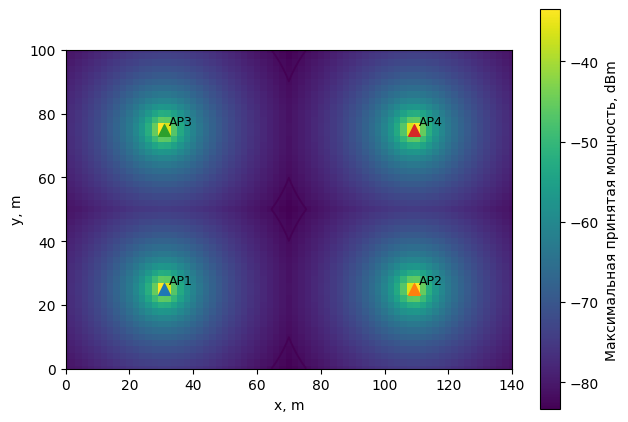

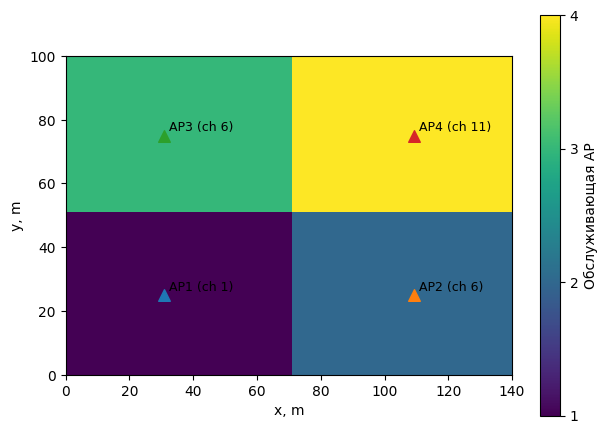

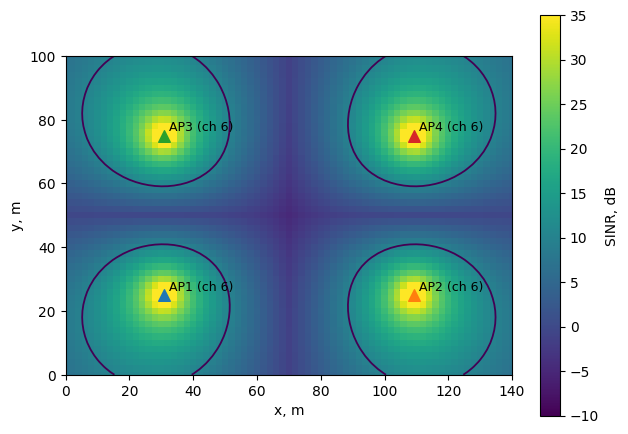

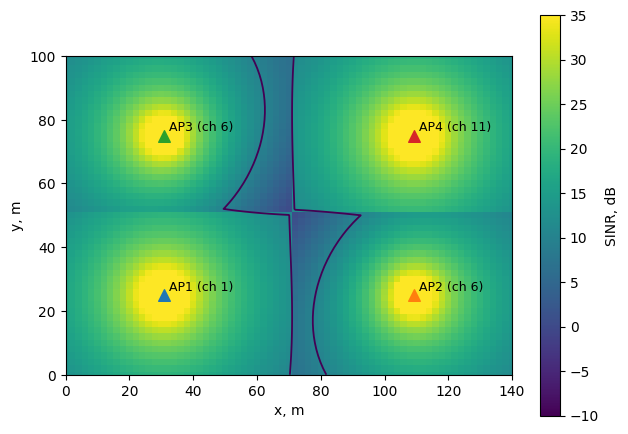

In [3]:
shape=results['Baseline']['X'].shape

def add_aps(ax, channels=None):
    for i,(x,y) in enumerate(aps):
        ax.scatter([x],[y],marker='^',s=70)
        label=f"AP{i+1}" if channels is None else f"AP{i+1} (ch {int(channels[i])})"
        ax.text(x+1.5,y+1.5,label,fontsize=9)
    ax.set_xlim(0,v['width_m']); ax.set_ylim(0,v['height_m'])
    ax.set_aspect('equal',adjustable='box'); ax.set_xlabel('x, m'); ax.set_ylabel('y, m')

plt.figure(figsize=(7.2,5.2)); ax=plt.gca()
im=ax.pcolormesh(results['Baseline']['X'],results['Baseline']['Y'],results['Baseline']['signal_dbm'].reshape(shape),shading='auto')
plt.colorbar(im,ax=ax,label='Максимальная принятая мощность, dBm')
ax.contour(results['Baseline']['X'],results['Baseline']['Y'],results['Baseline']['signal_dbm'].reshape(shape),levels=[v['rx_sensitivity_dbm']],linewidths=1.3)
add_aps(ax); plt.show()

plt.figure(figsize=(7.2,5.2)); ax=plt.gca()
im=ax.pcolormesh(results['Baseline']['X'],results['Baseline']['Y'],(results['Baseline']['serving']+1).reshape(shape),shading='nearest',vmin=1,vmax=4)
plt.colorbar(im,ax=ax,ticks=[1,2,3,4],label='Обслуживающая AP')
add_aps(ax,optimal_ch); plt.show()

for name in ['Baseline','Optimal']:
    r=results[name]
    plt.figure(figsize=(7.2,5.2)); ax=plt.gca()
    im=ax.pcolormesh(r['X'],r['Y'],r['sinr_db'].reshape(shape),shading='auto',vmin=-10,vmax=35)
    plt.colorbar(im,ax=ax,label='SINR, dB')
    ax.contour(r['X'],r['Y'],r['sinr_db'].reshape(shape),levels=[v['sinr_threshold_db']],linewidths=1.3)
    add_aps(ax,plans[name]); plt.show()


## 4. Валидация и sensitivity-анализ
Проанализируйте полный перебор 81 плана, декомпозицию outage, overlap, INR, сходимость по шагу сетки и sensitivity-тест +6 дБ.

,grid_step_m,n_grid_points,power_coverage_pct,sinr_coverage_pct,total_outage_pct,median_sinr_db,p5_sinr_db
0,4.0,936,98.718,91.667,8.333,18.113,8.822
1,2.0,3621,98.481,91.439,8.561,18.274,8.598
2,1.0,14241,98.560,91.426,8.574,18.444,8.513


,scenario,tx_delta_db,tx_power_dbm,power_coverage_pct,sinr_coverage_pct,power_outage_pct,interference_outage_pct,median_sinr_db,p5_sinr_db
0,Baseline,0.0,10.0,98.481,43.745,1.519,54.736,9.035,-0.392
1,Baseline,6.0,16.0,100.000,45.954,0.000,54.046,9.223,-0.568
2,Heuristic,0.0,10.0,98.481,91.439,1.519,7.042,18.274,8.598
3,Heuristic,6.0,16.0,100.000,93.703,0.000,6.297,22.621,9.064
4,Optimal,0.0,10.0,98.481,91.439,1.519,7.042,18.274,8.598
5,Optimal,6.0,16.0,100.000,93.731,0.000,6.269,22.621,9.064


,x_m,y_m,serving_ap,rssi_dbm,power_covered,sinr_baseline_db,sinr_covered_baseline,sinr_heuristic_db,sinr_covered_heuristic,sinr_optimal_db,sinr_covered_optimal
0,70.0,50.0,1,-83.409,False,-4.896,False,-0.364,False,10.581,False
1,30.0,24.0,1,-33.490,True,49.438,True,57.089,True,60.500,True
2,70.0,24.0,1,-81.042,True,-1.647,False,5.919,False,12.948,True
3,0.0,0.0,1,-81.202,True,6.750,False,11.323,True,12.787,True
4,140.0,50.0,2,-81.202,True,-0.511,False,12.787,True,10.520,True
5,70.0,100.0,3,-83.409,False,-1.404,False,10.581,False,6.297,False


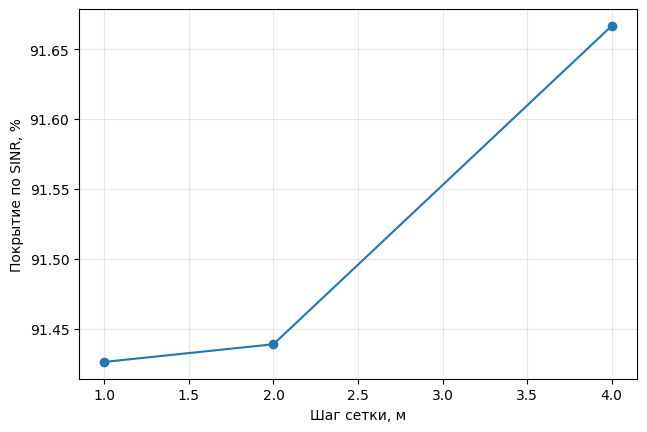

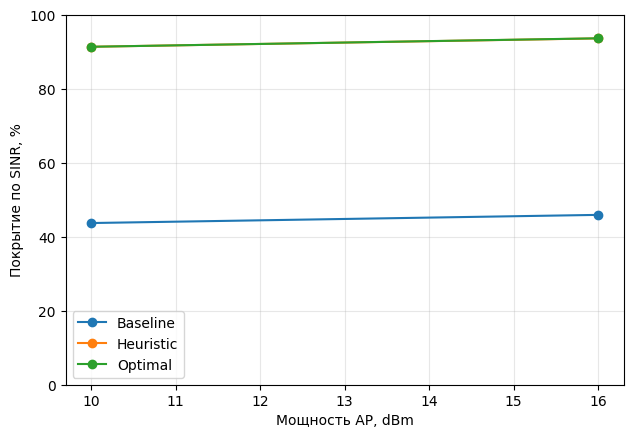

In [4]:
grid_conv_df = grid_convergence(v, optimal_ch, steps=(4.0,2.0,1.0))
power_sens_df = power_sensitivity(v, baseline_plan, heuristic_ch, optimal_ch, delta_db=6)
sample_df = sample_points_table(results)

display(grid_conv_df.round(3))
display(power_sens_df.round(3))
display(sample_df.round(3))

plt.figure(figsize=(7.2,4.8))
plt.plot(grid_conv_df['grid_step_m'],grid_conv_df['sinr_coverage_pct'],marker='o')
plt.xlabel('Шаг сетки, м'); plt.ylabel('Покрытие по SINR, %'); plt.grid(True,alpha=0.3); plt.show()

plt.figure(figsize=(7.2,4.8))
for name in ['Baseline','Heuristic','Optimal']:
    sub=power_sens_df[power_sens_df['scenario']==name]
    plt.plot(sub['tx_power_dbm'],sub['sinr_coverage_pct'],marker='o',label=name)
plt.xlabel('Мощность AP, dBm'); plt.ylabel('Покрытие по SINR, %'); plt.ylim(0,100); plt.grid(True,alpha=0.3); plt.legend(); plt.show()


## 5. Сохранение результатов в CSV

In [5]:
base=results['Baseline']; heur=results['Heuristic']; opt=results['Optimal']
grid_df=pd.DataFrame({
    'x_m':base['pts'][:,0], 'y_m':base['pts'][:,1], 'serving_ap':base['serving']+1,
    'strongest_rssi_dbm':base['signal_dbm'], 'power_covered':base['power_ok'],
    'sinr_baseline_db':base['sinr_db'], 'sinr_heuristic_db':heur['sinr_db'], 'sinr_optimal_db':opt['sinr_db'],
    'rf_overlap_ap_count':base['audible_count'],
    'cochannel_overlap_baseline':base['cochannel_overlap'],
    'cochannel_overlap_heuristic':heur['cochannel_overlap'],
    'cochannel_overlap_optimal':opt['cochannel_overlap'],
})
prefix=f'A3v2_variant_{VARIANT:02d}'
grid_df.to_csv(prefix+'_grid_results.csv',index=False)
metrics_df.to_csv(prefix+'_kpi.csv',index=False)
search_df.to_csv(prefix+'_channel_search_81.csv',index=False)
grid_conv_df.to_csv(prefix+'_grid_convergence.csv',index=False)
power_sens_df.to_csv(prefix+'_power_sensitivity.csv',index=False)
sample_df.to_csv(prefix+'_sample_points.csv',index=False)
print('Сохранено:', prefix+'_*.csv')

# Tekshiruv / Проверка
assert abs((results['Optimal']['metrics']['power_outage_pct'] + results['Optimal']['metrics']['interference_outage_pct']) - results['Optimal']['metrics']['total_outage_pct']) < 1e-9
assert results['Optimal']['metrics']['sinr_coverage_pct'] + 1e-12 >= results['Baseline']['metrics']['sinr_coverage_pct']
assert results['Optimal']['metrics']['sinr_coverage_pct'] + 1e-12 >= results['Heuristic']['metrics']['sinr_coverage_pct']


Сохранено: A3v2_variant_01_*.csv


## 6. Дополнительное advanced-расширение
Дополнительное усложнение: потери на стенах можно добавить как `PL_indoor = PL_CI + N_w L_w`. Этот пункт не является обязательным для основной оценки.

## 7. Вывод студента
В 10–12 предложениях объясните различия между baseline, эвристическим и оптимальным планами; power/interference outage, RF/co-channel overlap, INR, влияние шага сетки и sensitivity по мощности.